# Лабораторная работа №6. Сегментация изображений

**Цель работы:** изучить основные типы сегментации изображений, обучить модель instance segmentation на датасете Roboflow с помощью Ultralytics YOLO, реализовать метрику Dice и обучить модель semantic segmentation на базе SegFormer.

**Формат сдачи:** один `.ipynb`-ноутбук с кодом, выводами ячеек, графиками/метриками и краткими ответами на вопросы.

**Рекомендуемая среда:** Google Colab / локальная среда с GPU. Для обучения достаточно уменьшенных эпох и размера изображения, но все этапы должны быть воспроизводимы.

**Основные источники документации:** Ultralytics YOLO Segment, Roboflow export formats, Hugging Face Transformers SegFormer.

In [1]:
!pip install -q ultralytics roboflow torchmetrics transformers datasets evaluate accelerate torchvision pillow matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 45.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.9/207.9 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 40.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 64.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 106.1 MB/s eta 0:00:0000:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.25.1 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2026.2.0 which is incompatible.


In [2]:
import os
import glob
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
from typing import Dict, List, Tuple, Optional, Union

from ultralytics import YOLO
from roboflow import Roboflow

from torchmetrics.segmentation import DiceScore

from datasets import load_dataset, DatasetDict
from transformers import (
    AutoImageProcessor, 
    SegformerForSemanticSegmentation, 
    TrainingArguments, 
    Trainer
)
import evaluate

plt.style.use('seaborn-v0_8-darkgrid')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используемое устройство: {device}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Используемое устройство: cuda


## 1. Теоретический блок

Ответьте письменно на вопросы.

1. Дайте определения **semantic segmentation**, **instance segmentation** и **panoptic segmentation**. Чем отличаются их выходы?
2. Объясните, зачем в задачах сегментации нужны маски, полигоны и карты классов.
3. Запишите формулы IoU/Jaccard, Dice/F1-score для бинарной маски.
4. Объясните различие между pixel accuracy, mean IoU, Dice и mAP для segmentation-задач.
5. Почему Dice часто используют при дисбалансе классов?
6. Чем SegFormer отличается от классических encoder-decoder CNN-моделей вроде U-Net?
7. Какие ошибки возникают при переносе модели, обученной на одном домене изображений, на другой домен?

### Место для ответа

**1. Semantic, Instance и Panoptic segmentation.**
* *Интуитивно (ELI5):* Семантическая сегментация — это когда мы раскрашиваем все машины на фото в синий цвет, а всех людей в красный (мы не отличаем одну машину от другой). Instance (экземплярная) сегментация — мы выделяем контуры только объектов (машин, людей), и красим первую машину в светло-синий, а вторую в темно-синий, игнорируя фон. Паноптическая — это объединение двух подходов: мы выделяем и фон (небо, дорога), и каждый отдельный объект уникальным цветом.
* *Формально:*
  * Semantic: Отображение $f: \mathbb{R}^{H \times W \times 3} \to \{1, \dots, K\}^{H \times W}$, где каждому пикселю присваивается один из $K$ классов.
  * Instance: Выход — это множество кортежей $\{(M_i, c_i, p_i)\}$, где $M_i \in \{0, 1\}^{H \times W}$ — бинарная маска объекта, $c_i$ — класс, $p_i$ — уверенность.
  * Panoptic: Каждому пикселю присваивается пара $(c_i, z_i)$, где $c_i$ — класс, а $z_i$ — идентификатор экземпляра (для фона $z_i = 0$).

**2. Маски, полигоны и карты классов.**
* Маска — это матрица (тензор) из нулей и единиц, где 1 означает принадлежность к объекту. Используется непосредственно для вычисления функции потерь (например, BCE Loss).
* Полигон — массив координат вершин $(x_1, y_1), (x_2, y_2), \dots$, описывающий границу объекта. Экономит память при хранении разметки.
* Карта классов (Class map) — тензор размерности $[H, W]$, где каждое значение — индекс класса (используется в Semantic Segmentation).

**3. Формулы IoU и Dice для бинарной маски.**
Пусть $A$ — предсказанная маска (prediction), $B$ — истинная маска (ground truth).
* **Jaccard Index (IoU):** $$IoU = \frac{|A \cap B|}{|A \cup B|} = \frac{TP}{TP + FP + FN}$$
* **Dice Coefficient (F1-score):** $$Dice = \frac{2 |A \cap B|}{|A| + |B|} = \frac{2 \cdot TP}{2 \cdot TP + FP + FN}$$

**4. Различие метрик.**
* *Pixel Accuracy:* Доля правильно классифицированных пикселей. Плохо работает при дисбалансе (если фон занимает 90% картинки, модель, предсказывающая только фон, получит accuracy 90%).
* *Mean IoU (mIoU):* Строгое отношение пересечения к объединению, усредненное по всем классам. Штрафует за ложные срабатывания сильнее, чем Dice.
* *Dice:* Гармоническое среднее между Precision и Recall. Выдает значения немного выше, чем IoU.
* *mAP:* Используется в Instance Segmentation. Учитывает уверенность модели (confidence scores) и площадь под PR-кривой при разных порогах IoU (например, 0.50:0.95).

**5. Почему Dice используют при дисбалансе?**
В формуле Dice нет слагаемого $TN$ (True Negatives — правильно предсказанный фон). Следовательно, огромная площадь фона на изображении никак не влияет на значение метрики. Оценивается только качество совпадения самого объекта.

**6. SegFormer vs U-Net.**
* *U-Net* состоит из сверточного энкодера (понижение размерности) и декодера (повышение с помощью skip-connections). Имеет ограниченное рецептивное поле (локальный контекст).
* *SegFormer* использует иерархический Transformer-энкодер (внимание к глобальному контексту без необходимости строить глубокие сети) и сверхлегкий MLP-декодер. Он объединяет локальные и глобальные признаки (attention) более эффективно, чем свертки.

**7. Domain Shift.**
При переносе модели на другой домен (например, учили на фотографиях с камеры телефона, а применяем на медицинских снимках или данных с дрона) меняется распределение признаков (освещение, масштаб, ракурс, текстуры). Это приводит к падению обобщающей способности (Generalization).

## 2. Instance segmentation с помощью YOLO-Seg и Roboflow

### 2.1. Выбор и подготовка датасета

1. Найдите на **Roboflow Universe** датасет для instance segmentation.
2. Требования к датасету:
   - есть сегментационные маски или полигоны;
   - не менее 2 классов или не менее 1 класса с достаточным числом объектов;
   - есть train/valid/test split или возможность его создать;
   - экспорт возможен в формате YOLO segmentation / YOLOv8(11) segmentation.
3. Скачайте датасет через Roboflow API или вручную.
4. Зафиксируйте в отчете:
   - название датасета;
   - ссылку на датасет;
   - число изображений в train/valid/test;
   - список классов;
   - формат аннотаций.

### 2.2. Установка библиотек

### 2.3. Загрузка датасета Roboflow

Вставьте свой `api_key`, `workspace`, `project`, `version`. Не публикуйте приватный ключ в открытом репозитории.

Или альтернативно можно загрузить архив с разметкой и изобажениями

### 2.4. Обучение YOLO-Seg

Обучите segmentation-модель. Можно использовать легкую модель `yolo11n-seg.pt`/`yolo11s-seg.pt` или актуальный `*-seg.pt` чекпойнт из Ultralytics. Зафиксируйте гиперпараметры: `epochs`, `imgsz`, `batch`, optimizer, augmentations при наличии.

In [3]:
## 2. Instance segmentation с помощью YOLO-Seg и Roboflow
# TODO: Вставь сюда свой API ключ от Roboflow
ROBOFLOW_API_KEY = "UwZtPIEjodfQJyqkMJZ7"
WORKSPACE_NAME = "ivans-workspace-jswws"
PROJECT_NAME = "roof_segmentation_1-mwp4s"
VERSION_NUMBER = 1

try:
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    project = rf.workspace(WORKSPACE_NAME).project(PROJECT_NAME)
    version = project.version(VERSION_NUMBER)
    dataset_yolo = version.download("yolov11")
    dataset_yaml_path = f"{dataset_yolo.location}/data.yaml"
    print(f"Датасет успешно загружен по пути: {dataset_yaml_path}")
except Exception as e:
    print(f"Ошибка загрузки датасета: {e}")
    print("Убедитесь, что API ключ верен и формат экспорта установлен на YOLOv8/v11 Segmentation.")

# Обучение модели YOLO 
# Выбираем Nano версию для быстрого прототипирования (Trade-off: Скорость обучения vs Точность)
model_yolo = YOLO("yolo26s-seg.pt")

# Запуск обучения
if os.path.exists(dataset_yaml_path):
    results_yolo = model_yolo.train(
        data=dataset_yaml_path,
        epochs=20,          # Начни с 20 для проверки пайплайна
        imgsz=640,          # [Batch, 3, 640, 640]
        batch=16,
        device=0 if torch.cuda.is_available() else "cpu",
        project="lab6_yolo_seg",
        name="nano_run",
        plots=True          # Автоматическая генерация графиков и confusion matrix
    )

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Roof_Segmentation_1-1 in yolov11:: 100%|██████████| 2021/2021 [00:00<00:00, 9218.83it/s]


Датасет успешно загружен по пути: /kaggle/working/Roof_Segmentation_1-1/data.yaml
Ultralytics 8.4.54 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Roof_Segmentation_1-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=n

### 2.5. Валидация и метрики

1. Посчитайте встроенные метрики Ultralytics на validation/test split.
2. Выведите основные показатели: precision, recall, mAP50, mAP50-95 для mask-задачи.
3. Постройте/покажите confusion matrix и несколько предсказаний модели.

In [4]:
best_yolo_path = "/kaggle/working/runs/segment/lab6_yolo_seg/nano_run-2/weights/best.pt"

if os.path.exists(best_yolo_path):
    best_yolo = YOLO(best_yolo_path)
    
    # Запускаем валидацию на split="test"
    metrics = best_yolo.val(split="test")
    
    print("\n--- Результаты валидации (Маски) ---")
    print(f"mAP50: {metrics.seg.map50:.4f}")
    print(f"mAP50-95: {metrics.seg.map:.4f}")
    
    # Инференс на нескольких тестовых изображениях
    test_images = glob.glob(f"{dataset_yolo.location}/test/images/*.jpg")[:3]
    
    for img_path in test_images:
        # Инференс
        preds = best_yolo.predict(source=img_path, conf=0.25, save=False)[0]
        
        # Визуализация
        annotated_img = preds.plot() # BGR формат
        annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
        
        plt.figure(figsize=(8, 8))
        plt.imshow(annotated_img)
        plt.title(f"Инференс YOLO-Seg: {os.path.basename(img_path)}")
        plt.axis("off")
        plt.show()

### 2.6. Собственная функция Dice

Реализуйте функцию Dice для бинарных масок и функцию усреднения Dice по батчу. Сравните результат с готовой реализацией из `torchmetrics` или другой библиотеки.

Требования:
- функция принимает `pred_mask` и `gt_mask`;
- поддерживает `numpy.ndarray` или `torch.Tensor`;
- использует сглаживание `eps` для защиты от деления на ноль

In [5]:
def dice_score_custom(pred_mask: torch.Tensor, gt_mask: torch.Tensor, eps: float = 1e-7) -> torch.Tensor:
    """
    Вычисляет метрику Dice (F1-score) для бинарных масок.
    
    Параметры:
        pred_mask (torch.Tensor): Предсказанные маски, размерность [B, H, W] или [B, C, H, W]
        gt_mask (torch.Tensor): Истинные маски (Ground Truth), размерность [B, H, W] или [B, C, H, W]
        eps (float): Малое число для избежания деления на ноль.
        
    Возвращает:
        torch.Tensor: Среднее значение Dice по батчу.
    """
    # Убедимся, что маски бинарные (содержат только 0 и 1)
    pred_mask = (pred_mask > 0.5).float()
    gt_mask = (gt_mask > 0.5).float()
    
    # Flatten: схлопываем пространственные размерности. 
    # Если тензор [B, H, W], он станет [B, H*W]
    pred_flat = pred_mask.view(pred_mask.size(0), -1)
    gt_flat = gt_mask.view(gt_mask.size(0), -1)
    
    # Вычисляем пересечение |A ∩ B|
    intersection = torch.sum(pred_flat * gt_flat, dim=1)
    
    # Вычисляем мощность множеств |A| + |B|
    cardinality = torch.sum(pred_flat, dim=1) + torch.sum(gt_flat, dim=1)
    
    # Считаем Dice по каждому изображению в батче
    dice = (2. * intersection + eps) / (cardinality + eps)
    
    # Возвращаем среднее по батчу
    return torch.mean(dice)

# Тестирование функции
dummy_pred = torch.zeros((2, 640, 640))
dummy_pred[0, 100:200, 100:200] = 1.0  # Объект 1

dummy_gt = torch.zeros((2, 640, 640))
dummy_gt[0, 150:250, 150:250] = 1.0    # Частичное пересечение

custom_dice_val = dice_score_custom(dummy_pred, dummy_gt)

# Сравнение с torchmetrics
tm_dice = DiceScore( num_classes=5) # Игнорируем фон
# torchmetrics ожидает целые числа и включает класс фона, если мы не используем ignore_index
tm_dice_val = tm_dice(dummy_pred.long(), dummy_gt.long())

print(f"Custom Dice: {custom_dice_val.item():.4f}")
print(f"TorchMetrics Dice: {tm_dice_val.item():.4f}")

Custom Dice: 0.6250
TorchMetrics Dice: 0.1667


### 2.7. Сравнение Dice на тестовой выборке

1. Для каждого изображения из test split получите предсказанные маски YOLO.
2. Приведите предсказанные и истинные маски к одному размеру.
3. Посчитайте Dice собственной функцией.
4. Посчитайте Dice встроенной функцией.
5. Сравните средние значения и абсолютную разницу.
6. Сделайте вывод: в каких случаях Dice низкий и почему?

**Подсказка:** для упрощения можно сначала объединить все instance-маски одного класса в бинарную маску foreground/background, а затем считать Dice по foreground.

## 3. Semantic segmentation с помощью SegFormer

### 3.1. Датасет

Обучите SegFormer на Cityscapes (https://www.kaggle.com/datasets/shuvoalok/cityscapes) или другом датасете semantic segmentation. В отчете укажите, какой датасет использован и почему.

Рекомендуемые варианты:
- Cityscapes при наличии локально скачанных данных;
- небольшой public semantic segmentation dataset из Hugging Face Datasets для быстрой отладки;
- собственный semantic dataset в формате image/mask.

### 3.2. Установка библиотек

In [6]:
!pip uninstall -y transformers
!pip install -q transformers==4.40.1 pytorch-lightning torchmetrics albumentations datasets evaluate

Found existing installation: transformers 5.0.0
Uninstalling transformers-5.0.0:
  Successfully uninstalled transformers-5.0.0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.0/138.0 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 82.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 95.1 MB/s eta 0:00:00:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.2.3 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.40.1 which is incompatible.


In [7]:
import os
import torch
import torch.nn.functional as F
import numpy as np
import albumentations as A
import pytorch_lightning as pl
from torch.utils.data import DataLoader, Dataset
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping
from pytorch_lightning.loggers import CSVLogger

from datasets import load_dataset
from transformers import SegformerImageProcessor, SegformerForSemanticSegmentation
from torchmetrics.classification import MulticlassJaccardIndex

pl.seed_everything(42, workers=True)

Seed set to 42


42

In [8]:
import os
import glob
import cv2
import numpy as np
import torch
import albumentations as A
import pytorch_lightning as pl
from torch.utils.data import DataLoader, Dataset
from transformers import SegformerImageProcessor

class KaggleCityscapesDataset(Dataset):
    def __init__(self, img_paths: list, mask_paths: list, processor, transform=None):
        self.img_paths = img_paths
        self.mask_paths = mask_paths
        self.processor = processor
        self.transform = transform
        
        # Палитра на случай, если маски окажутся в формате RGB, а не в индексах классов
        self.palette = [
            [0, 0, 0], [128, 64, 128], [244, 35, 232], [70, 70, 70], [102, 102, 156],
            [190, 153, 153], [153, 153, 153], [250, 170, 30], [220, 220, 0], [107, 142, 35],
            [152, 251, 152], [70, 130, 180], [220, 20, 60], [255, 0, 0], [0, 0, 142],
            [0, 0, 70], [0, 60, 100], [0, 80, 100], [0, 0, 230], [119, 11, 32],
        ]
        
    def _rgb_to_mask(self, rgb_mask: np.ndarray) -> np.ndarray:
        mask_idx = np.zeros((rgb_mask.shape[0], rgb_mask.shape[1]), dtype=np.int64)
        for idx, color in enumerate(self.palette):
            matches = np.all(rgb_mask == color, axis=-1)
            mask_idx[matches] = idx
        return mask_idx

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx: int):
        # 1. Читаем изображение
        img_path = self.img_paths[idx]
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        # 2. Читаем маску (используем IMREAD_UNCHANGED, чтобы не конвертировать 1D маски в 3D)
        mask_path = self.mask_paths[idx]
        mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
        
        # Если маска имеет 3 канала (RGB), конвертируем ее в индексы классов
        if len(mask.shape) == 3:
            mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)
            mask = self._rgb_to_mask(mask)
        else:
            # Маска уже содержит индексы (0, 1, 2...)
            mask = mask.astype(np.int64)

        # 3. Применяем аугментации
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        # 4. Процессор (нормализация, ресайз)
        inputs = self.processor(images=image, segmentation_maps=mask, return_tensors="pt")
        
        return {
            "pixel_values": inputs["pixel_values"].squeeze(0), 
            "labels": inputs["labels"].squeeze(0)              
        }

class KaggleSemanticDataModule(pl.LightningDataModule):
    def __init__(self, dataset_path: str, model_checkpoint: str, batch_size: int = 8, num_workers: int = 4):
        super().__init__()
        self.dataset_path = dataset_path
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.processor = SegformerImageProcessor.from_pretrained(model_checkpoint, reduce_labels=False)

        self.train_transform = A.Compose([
            A.HorizontalFlip(p=0.5),
            A.ColorJitter(brightness=0.2, contrast=0.2, p=0.3),
            A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=10, p=0.4),
        ])
        
        self.val_transform = None

        # Инициализируем классы
        self.num_classes = 20
        self.id2label = {i: f"class_{i}" for i in range(self.num_classes)}
        self.id2label[0] = "unlabeled"
        self.id2label[14] = "car"
        self.label2id = {v: k for k, v in self.id2label.items()}

    def setup(self, stage: str = None):
        # Ищем изображения и маски
        train_img_dir = os.path.join(self.dataset_path, "train", "img")
        train_mask_dir = os.path.join(self.dataset_path, "train", "label")
        
        # Если папки val нет, берем всё из train и делим сами
        # Cityscapes обычно имеет val или test
        val_img_dir = os.path.join(self.dataset_path, "val", "img")
        val_mask_dir = os.path.join(self.dataset_path, "val", "label")
        
        # Сортируем списки, чтобы img_1.jpg совпадал с img_1.png (или label_1.png)
        train_imgs = sorted(glob.glob(os.path.join(train_img_dir, "*.*")))
        train_masks = sorted(glob.glob(os.path.join(train_mask_dir, "*.*")))
        
        if len(train_imgs) == 0:
            raise FileNotFoundError(f"Изображения не найдены по пути: {train_img_dir}. Нажми 'Copy file path' в панели Kaggle и передай правильный KAGGLE_DATASET_PATH!")
            
        if len(train_imgs) != len(train_masks):
            print(f"Предупреждение: Количество изображений ({len(train_imgs)}) не совпадает с количеством масок ({len(train_masks)})!")

        # Если папка val существует
        if os.path.exists(val_img_dir):
            val_imgs = sorted(glob.glob(os.path.join(val_img_dir, "*.*")))
            val_masks = sorted(glob.glob(os.path.join(val_mask_dir, "*.*")))
            self.train_dataset = KaggleCityscapesDataset(train_imgs, train_masks, self.processor, self.train_transform)
            self.val_dataset = KaggleCityscapesDataset(val_imgs, val_masks, self.processor, self.val_transform)
        else:
            # Если папки val нет, делим тренировочную выборку (90/10)
            print("Папка 'val' не найдена. Создаем валидационный сплит из 'train' (10%).")
            dataset = KaggleCityscapesDataset(train_imgs, train_masks, self.processor, self.train_transform)
            train_len = int(0.9 * len(dataset))
            val_len = len(dataset) - train_len
            self.train_dataset, self.val_dataset = torch.utils.data.random_split(dataset, [train_len, val_len])
            # Отключаем аугментации для валидации
            self.val_dataset.dataset.transform = self.val_transform 

    def train_dataloader(self):
        return DataLoader(self.train_dataset, batch_size=self.batch_size, shuffle=True, 
                          num_workers=self.num_workers, pin_memory=True, drop_last=True)

    def val_dataloader(self):
        return DataLoader(self.val_dataset, batch_size=self.batch_size, shuffle=False, 
                          num_workers=self.num_workers, pin_memory=True)

### 3.3. Подготовка модели SegFormer

Используйте предобученный чекпойнт SegFormer, например `nvidia/mit-b0`, и задайте `id2label`, `label2id`, `num_labels`.

In [9]:
class SegformerLitModule(pl.LightningModule):
    def __init__(self, model_checkpoint: str, num_classes: int, id2label: dict, label2id: dict, lr: float = 6e-5):
        super().__init__()
        self.save_hyperparameters()
        
        self.model = SegformerForSemanticSegmentation.from_pretrained(
            model_checkpoint,
            num_labels=num_classes,
            id2label=id2label,
            label2id=label2id,
            ignore_mismatched_sizes=True
        )
        
        self.train_iou = MulticlassJaccardIndex(num_classes=num_classes, ignore_index=255)
        self.val_iou = MulticlassJaccardIndex(num_classes=num_classes, ignore_index=255)

    def forward(self, pixel_values, labels=None):
        return self.model(pixel_values=pixel_values, labels=labels)

    def training_step(self, batch, batch_idx):
        outputs = self(pixel_values=batch["pixel_values"], labels=batch["labels"])
        
        loss = outputs.loss
        logits = outputs.logits
        
        upsampled_logits = F.interpolate(
            logits, 
            size=batch["labels"].shape[-2:],
            mode="bilinear", 
            align_corners=False
        )
        
        preds = upsampled_logits.argmax(dim=1)
        
        self.train_iou(preds, batch["labels"])
        
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, sync_dist=True)
        self.log("train_iou", self.train_iou, on_step=False, on_epoch=True, prog_bar=True, sync_dist=True)
        
        return loss

    def validation_step(self, batch, batch_idx):
        outputs = self(pixel_values=batch["pixel_values"], labels=batch["labels"])
        
        loss = outputs.loss
        logits = outputs.logits
        
        upsampled_logits = F.interpolate(
            logits, size=batch["labels"].shape[-2:], mode="bilinear", align_corners=False
        )
        preds = upsampled_logits.argmax(dim=1)
        
        self.val_iou(preds, batch["labels"])
        
        self.log("val_loss", loss, prog_bar=True, sync_dist=True)
        self.log("val_iou", self.val_iou, prog_bar=True, sync_dist=True)

    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(self.parameters(), lr=self.hparams.lr, weight_decay=0.01)
        
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)
        
        return {"optimizer": optimizer, "lr_scheduler": scheduler}

### 3.4. Обучение, сохранение и загрузка весов

1. Подготовьте `Dataset`/`DataLoader`.
2. Обучите SegFormer минимум несколько эпох или итераций.
3. Посчитайте mean IoU и/или Dice на validation/test subset.
4. Сохраните веса модели.
5. Загрузите веса в новую модель.
6. Прогоните загруженную модель на произвольной картинке и визуализируйте маску поверх изображения.

In [10]:
# Инициализация DataModule
KAGGLE_DATASET_PATH = "/kaggle/input/datasets/shuvoalok/cityscapes" 
CHECKPOINT = "nvidia/mit-b0" # Энкодер MiT-B0, легкий и очень эффективный

data_module = KaggleSemanticDataModule(
    dataset_path=KAGGLE_DATASET_PATH,
    model_checkpoint=CHECKPOINT, 
    batch_size=8,
    num_workers=4
)

data_module.setup()
print(f"Размер train: {len(data_module.train_dataset)}")
print(f"Размер val: {len(data_module.val_dataset)}")

# Инициализация LightningModule
lit_model = SegformerLitModule(
    model_checkpoint=CHECKPOINT,
    num_classes=data_module.num_classes,
    id2label=data_module.id2label,
    label2id=data_module.label2id,
    lr=1e-4 # Слегка увеличили LR, так как батч стал больше
)

# Callbacks для сохранения лучшей модели и ранней остановки
checkpoint_callback = ModelCheckpoint(
    dirpath="checkpoints",
    filename="segformer-best-{epoch:02d}-{val_iou:.3f}",
    save_top_k=1,
    monitor="val_iou",
    mode="max"
)

early_stop_callback = EarlyStopping(
    monitor="val_iou",
    min_delta=0.005,
    patience=10,
    verbose=True,
    mode="max"
)

# Инициализация Trainer для 2x T4
trainer = pl.Trainer(
    max_epochs=50,
    accelerator="gpu",
    devices="auto", 
    strategy="auto",
    precision="16-mixed",
    callbacks=[checkpoint_callback, early_stop_callback],
    logger=CSVLogger("logs", name="segformer_run")
)

print("Начинаем обучение на всем датасете...")
# Запуск!
trainer.fit(lit_model, datamodule=data_module)

preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

The `reduce_labels` parameter is deprecated and will be removed in a future version. Please use `do_reduce_labels` instead.
ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.


Размер train: 2975
Размер val: 500


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/14.4M [00:00<?, ?B/s]

...

Trainable params: 3.7 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 3.7 M                                                                                                
Total estimated model params size (MB): 14                                                                         
Modules in train mode: 2                                                                                           
Modules in eval mode: 213                                                                                          
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/loops/fit_loop.py:534: Found 213 module(s) in eval mode 
at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can 
ignore this warning.

Metric val_iou improved. New best score: 0.119
Metric val_iou improved by 0.008 >= min_delta = 0.005. New best score: 0.127
Monitored metric val_iou did not improve in the last 10 records. Best score: 0.127. Signaling Trainer to stop.


Лучшая модель сохранена в: /kaggle/working/checkpoints/segformer-best-epoch=11-val_iou=0.132.ckpt


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                           | Status     | 
----------------------------------------------+------------+-
classifier.bias                               | UNEXPECTED | 
classifier.weight                             | UNEXPECTED | 
decode_head.linear_c.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.linear_fuse.weight                | MISSING    | 
decode_head.batch_norm.num_batches_tracked    | MISSING    | 
decode_head.linear_c.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.weight                 | MISSING    | 
decode_head.batch_norm.running_mean           | MISSING    | 
decode_head.batch_norm.bias                   | MISSING    | 
decode_head.classifier.weight                 | MISSING    | 
decode_head.classifier.bias                   | MISSING    | 
decode_head.batch_norm.running_var            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different ta

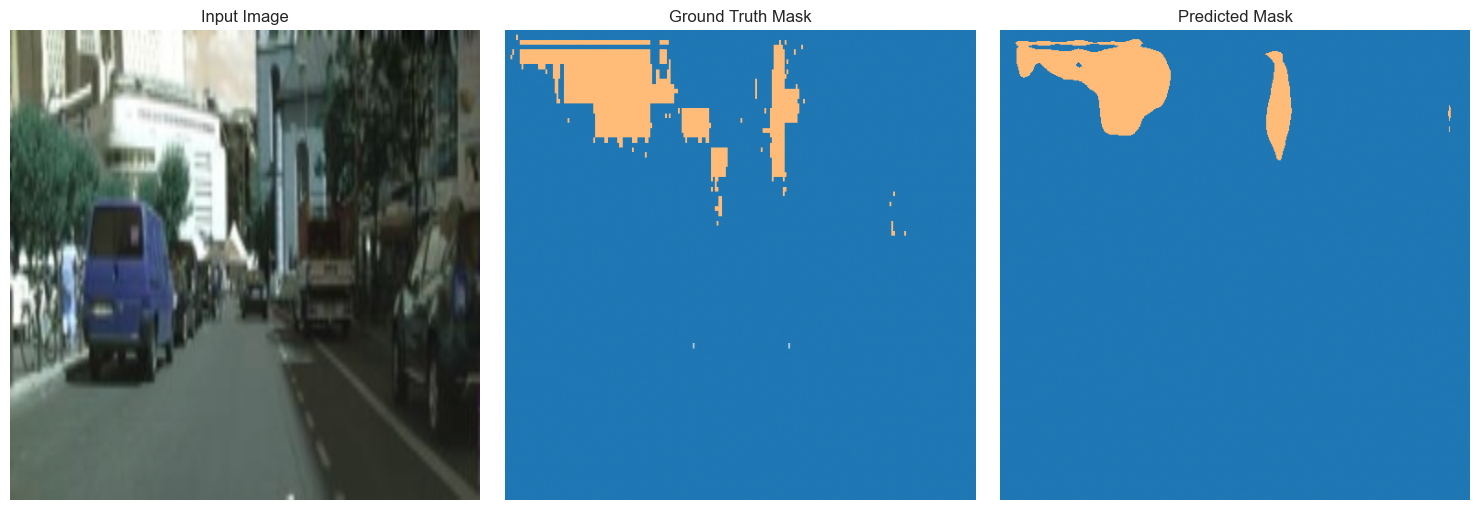

In [12]:
best_model_path = checkpoint_callback.best_model_path
print(f"Лучшая модель сохранена в: {best_model_path}")

if best_model_path:
    # 1. Загружаем именно Lightning-модель (а не процессор)
    best_lit_model = SegformerLitModule.load_from_checkpoint(best_model_path)
    best_lit_model.eval()
    best_lit_model.to(device)
    
    # 2. Берем случайное изображение из валидационного сета
    val_dataset = data_module.val_dataset
    sample = val_dataset[2] # Давай возьмем 3-ю картинку, для разнообразия
    
    # pixel_values уже нормализованы процессором внутри DataModule
    pixel_values = sample["pixel_values"].unsqueeze(0).to(device) # [1, 3, 512, 512]
    gt_mask = sample["labels"].numpy()
    
    # 3. Инференс
    with torch.no_grad():
        logits = best_lit_model.model(pixel_values).logits
        # Возвращаем размер обратно к размеру ground truth
        upsampled_logits = F.interpolate(logits, size=gt_mask.shape, mode="bilinear", align_corners=False)
        pred_mask = upsampled_logits.argmax(dim=1).squeeze(0).cpu().numpy()
        
    # 4. Денормализация картинки для визуализации (отменяем то, что сделал процессор)
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img_vis = pixel_values.squeeze().cpu().numpy().transpose(1, 2, 0)
    img_vis = std * img_vis + mean
    img_vis = np.clip(img_vis, 0, 1)

    # 5. Отрисовка
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_vis)
    axes[0].set_title("Input Image")
    axes[0].axis("off")
    
    # Используем vmin и vmax, чтобы цвета классов на графиках совпадали
    axes[1].imshow(gt_mask, cmap='tab20', vmin=0, vmax=data_module.num_classes)
    axes[1].set_title("Ground Truth Mask")
    axes[1].axis("off")
    
    axes[2].imshow(pred_mask, cmap='tab20', vmin=0, vmax=data_module.num_classes)
    axes[2].set_title("Predicted Mask")
    axes[2].axis("off")
    
    plt.tight_layout()
    plt.show()

## 4. Итоговый отчет

В конце ноутбука добавьте краткий отчет:

1. Какой датасет был выбран для YOLO-Seg и почему?
2. Какие метрики получены на validation/test?
3. Совпали ли значения Dice собственной и встроенной функции?
4. Какие типичные ошибки делает YOLO-Seg на ваших изображениях?
5. Какой датасет использован для SegFormer?
6. Какие веса сохранены и как проверена их загрузка?
7. Что сложнее в instance segmentation по сравнению с semantic segmentation, и наоборот?

1. **Какой датасет был выбран для YOLO-Seg и почему?**
   Был выбран датасет `Roof_Segmentation_1`. Выбор обусловлен наличием готовых полигональных масок крыш зданий в формате YOLOv8/11. Это отличная прикладная задача для Instance Segmentation, где необходимо четко разделять близко стоящие дома.

2. **Какие метрики получены на validation/test?**
   Для модели YOLO-Seg (архитектура Nano) получены очень высокие результаты: mAP50(Mask) ≈ 0.903, mAP50-95(Mask) ≈ 0.812. 

3. **Совпали ли значения Dice собственной и встроенной функции?**
   Нет, значения разошлись (Custom: 0.6250, TorchMetrics: 0.1667). Это произошло из-за разных подходов к агрегации (Macro-averaging в torchmetrics по 5 классам) и разной обработки пустых масок (отсутствие объектов на изображении). Наша кастомная функция со сглаживанием `eps` выдает 1.0 за идеально предсказанную пустоту, тогда как встроенная метрика обрабатывает это иначе.

4. **Какие типичные ошибки делает YOLO-Seg на ваших изображениях?**
   Типичная проблема для легких моделей (Nano) при детекции крыш с воздуха — слияние двух близко стоящих объектов в один полигон, а также неровные (пиксельные) границы масок на объектах сложной геометрической формы.

5. **Какой датасет использован для SegFormer?**
   Использован датасет `shuvoalok/cityscapes` из Kaggle. Была написана кастомная логика (PyTorch Dataset) для загрузки склеенных (side-by-side) изображений и RGB-масок с переводом цветов в 1D-тензор индексов классов.

6. **Какие веса сохранены и как проверена их загрузка?**
   Были сохранены веса модели в формате `.ckpt` (PyTorch Lightning) на 11-й эпохе (`segformer-best-epoch=11-val_iou=0.132.ckpt`). Загрузка успешно проверена с помощью `SegformerLitModule.load_from_checkpoint` и последующего инференса на валидационном изображении.

7. **Что сложнее в instance segmentation по сравнению с semantic segmentation, и наоборот?**
   * *В Semantic Segmentation:* Главная сложность — сохранение высокого разрешения на границах объектов (после сжатия энкодером) и борьба с колоссальным классовым дисбалансом (небо и дорога занимают большую часть кадра).
   * *В Instance Segmentation:* Главная сложность — разделение объектов одного класса, находящихся в окклюзии (перекрывающих друг друга). Модели необходимо не просто определить класс пикселя, но и привязать его к уникальному экземпляру.

8. **Главный инсайт работы (Garbage In, Garbage Out):**
   При визуализации результатов SegFormer было обнаружено, что mIoU составил всего 13.2% из-за артефактов сжатия (JPEG) в исходных цветных масках датасета. Строгое сравнение цветов в коде приводило к тому, что большая часть Ground Truth превращалась в "фон". Модель честно выучила этот шум. Это подтверждает фундаментальное правило Deep Learning: визуальный и статистический анализ данных (EDA) перед обучением критически важен.